In [2]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

In [3]:
#im going to import the csv file now and read its contents
Bestsellers = pd.read_csv('bestsellers with categories.csv')
Bestsellers.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [4]:
#I want to know how many records are in dataset
Bestsellers.shape

(550, 7)

In [5]:
#no null values present in dataset
Bestsellers.info()

<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    str    
 1   Author       550 non-null    str    
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 68.7 KB


In [6]:
#changed the year column to datetime format
Bestsellers['Year'] = pd.to_datetime(Bestsellers['Year'], format='%Y')
Bestsellers.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016-01-01,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011-01-01,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018-01-01,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017-01-01,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019-01-01,Non Fiction


In [7]:
Bestsellers.info()

<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Name         550 non-null    str           
 1   Author       550 non-null    str           
 2   User Rating  550 non-null    float64       
 3   Reviews      550 non-null    int64         
 4   Price        550 non-null    int64         
 5   Year         550 non-null    datetime64[us]
 6   Genre        550 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 68.7 KB


In [8]:
#drop duplicate records from the dataset
Bestsellers.duplicated()
Bestsellers.drop_duplicates(inplace=True)

In [9]:
Bestsellers.style.format({'Price': '${:,.2f}'})

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.700000,17350,$8.00,2016-01-01 00:00:00,Non Fiction
1,11/22/63: A Novel,Stephen King,4.600000,2052,$22.00,2011-01-01 00:00:00,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.700000,18979,$15.00,2018-01-01 00:00:00,Non Fiction
3,1984 (Signet Classics),George Orwell,4.700000,21424,$6.00,2017-01-01 00:00:00,Fiction
4,"5,000 Awesome Facts (About Everything!) (National Geographic Kids)",National Geographic Kids,4.800000,7665,$12.00,2019-01-01 00:00:00,Non Fiction
5,A Dance with Dragons (A Song of Ice and Fire),George R. R. Martin,4.400000,12643,$11.00,2011-01-01 00:00:00,Fiction
6,A Game of Thrones / A Clash of Kings / A Storm of Swords / A Feast of Crows / A Dance with Dragons,George R. R. Martin,4.700000,19735,$30.00,2014-01-01 00:00:00,Fiction
7,A Gentleman in Moscow: A Novel,Amor Towles,4.700000,19699,$15.00,2017-01-01 00:00:00,Fiction
8,"A Higher Loyalty: Truth, Lies, and Leadership",James Comey,4.700000,5983,$3.00,2018-01-01 00:00:00,Non Fiction
9,A Man Called Ove: A Novel,Fredrik Backman,4.600000,23848,$8.00,2016-01-01 00:00:00,Fiction


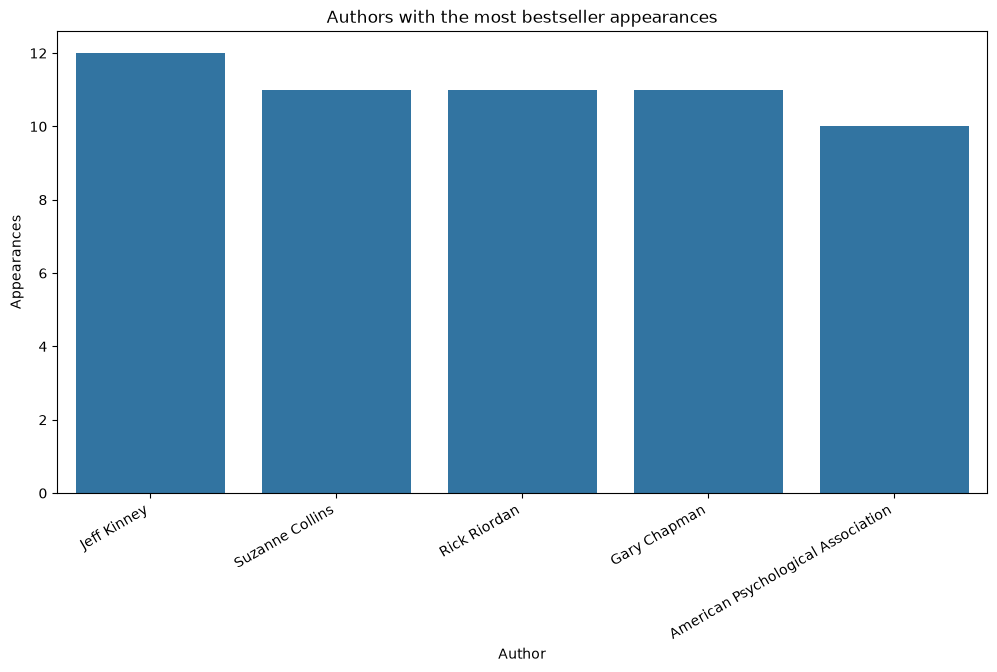

In [24]:
top_authors = Bestsellers["Author"].value_counts().head(5).reset_index()
top_authors.columns = ["Author", "Appearances"]

plt.figure(figsize=(12, 6))
sns.barplot(data=top_authors, x="Author", y="Appearances")
plt.title("Authors with the most bestseller appearances")
plt.xticks(rotation=30, ha="right")
plt.show()

<Axes: xlabel='Name', ylabel='Reviews'>

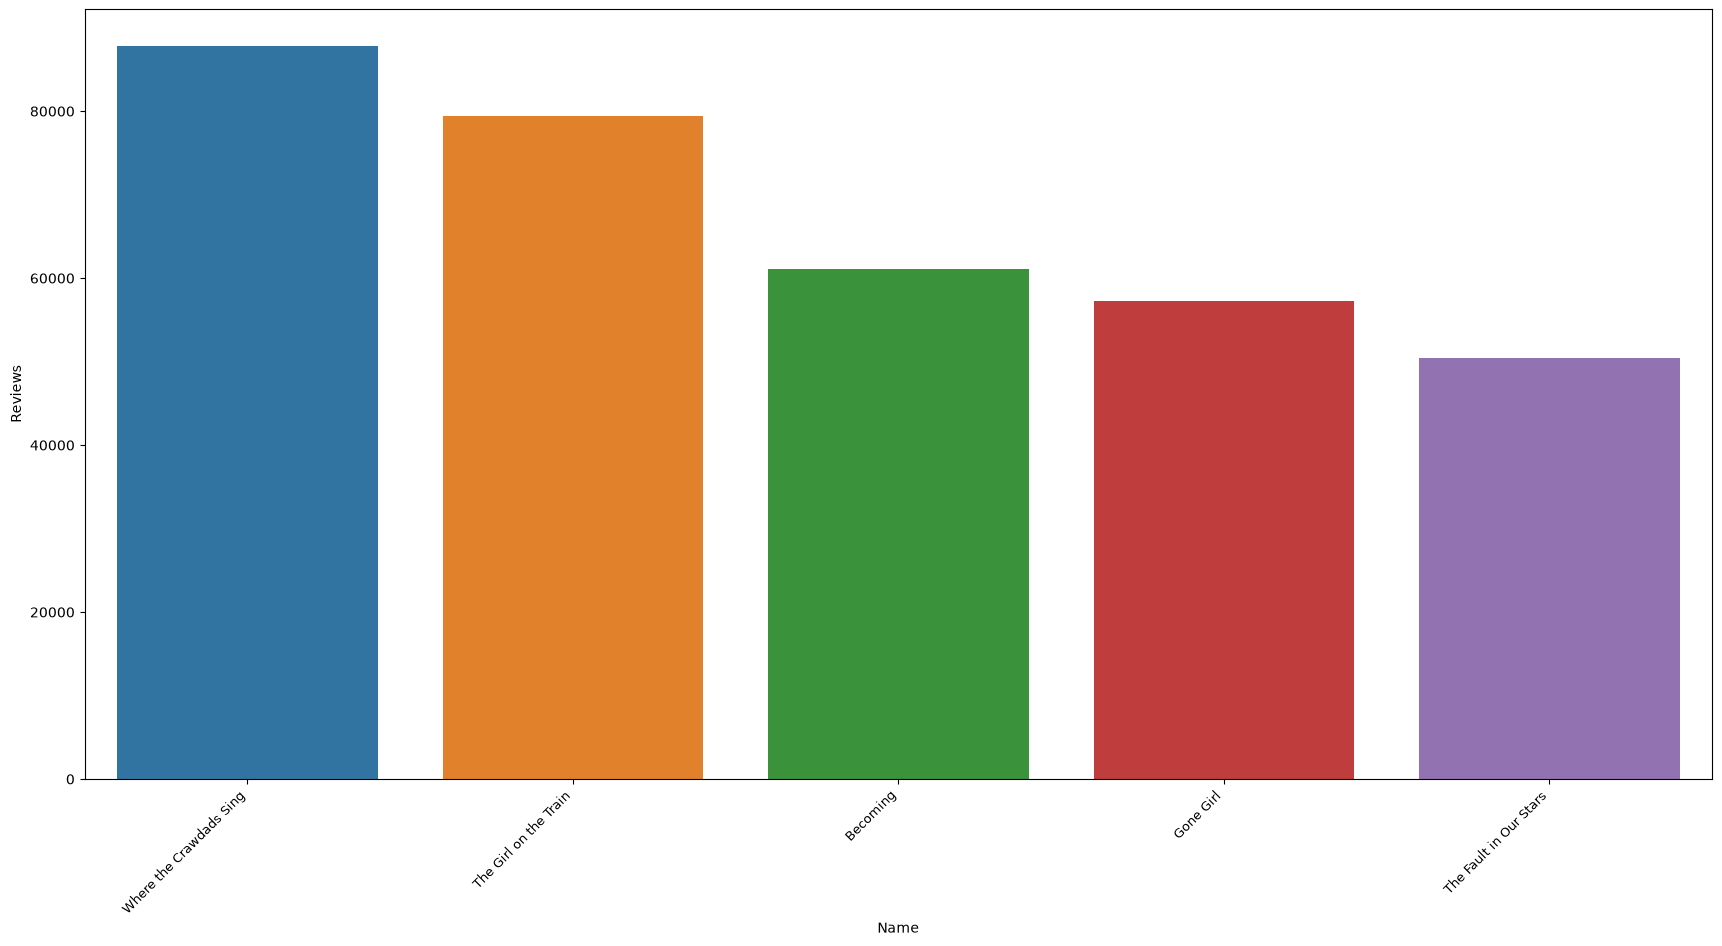

In [ ]:
#top 5 most reviewed books on amazon
plt.figure(figsize=(21,10))
plt.xticks(rotation=45, ha="right", fontsize=9)
top_reviewd = Bestsellers.groupby('Name')['Reviews'].mean().nlargest(5).reset_index()
sns.barplot(data=top_reviewd, x='Name', y='Reviews', hue ='Name')

<Axes: xlabel='Year', ylabel='Price'>

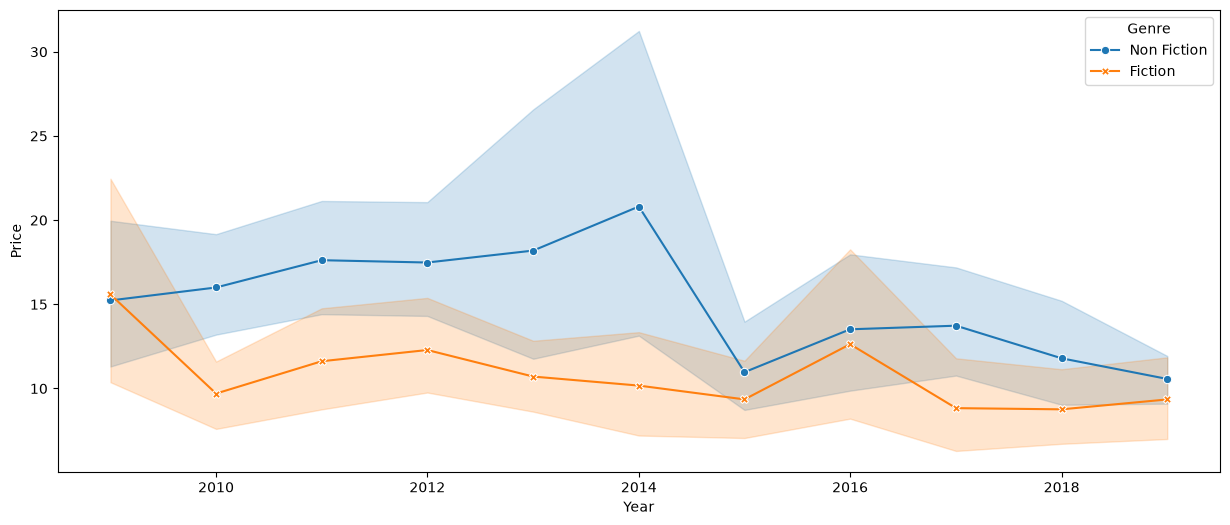

In [12]:
#sales across the years fiction and non-fiction books
plt.figure(figsize=(15,6))
sns.lineplot(data = Bestsellers, x ='Year', y = 'Price' , hue = 'Genre', style = 'Genre', markers = True, dashes = False)

<Axes: xlabel='Year', ylabel='Price'>

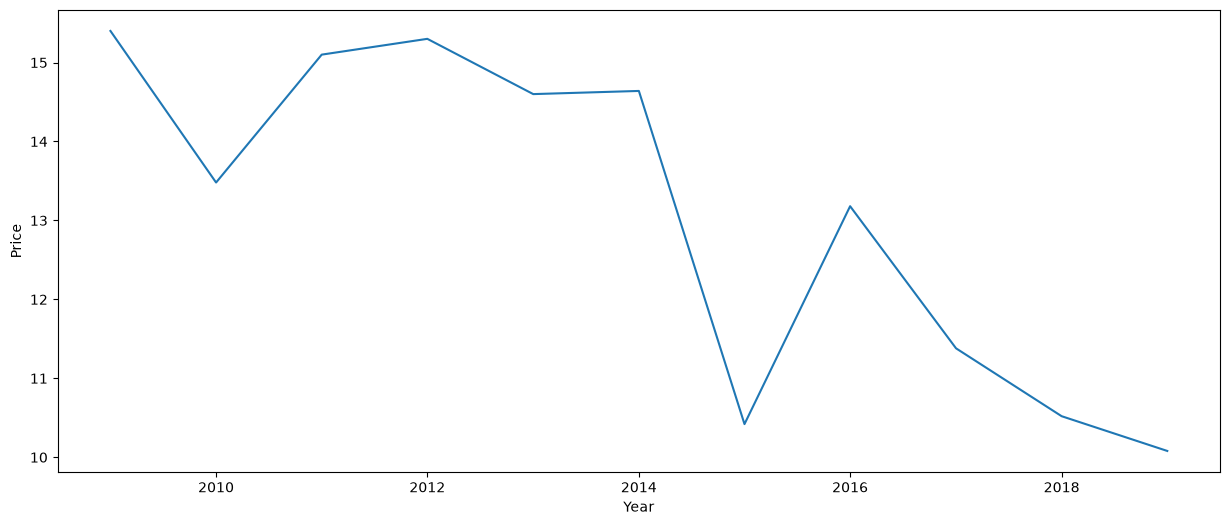

In [13]:
# average sales across the years 
plt.figure(figsize=(15,6))
sns.lineplot(data = Bestsellers.groupby('Year')['Price'].mean().reset_index(), x ='Year', y = 'Price' , markers = True, dashes = False)

<Axes: xlabel='Year', ylabel='Price'>

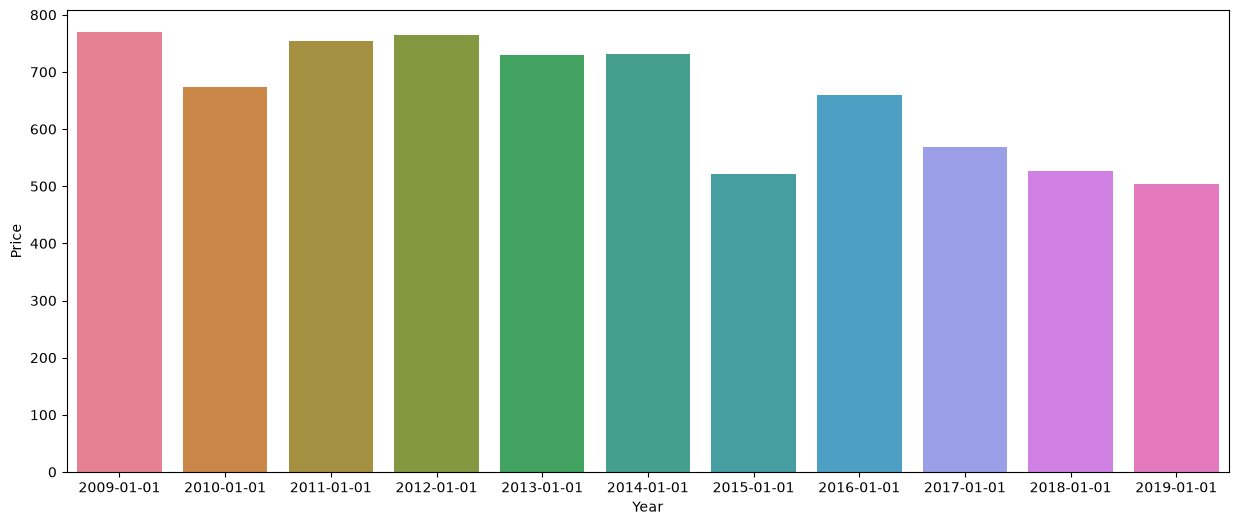

In [14]:
#total sales across the years
plt.figure(figsize=(15,6))
sns.barplot(data = Bestsellers.groupby('Year')['Price'].sum().reset_index(), x ='Year', y = 'Price' , hue = 'Year')

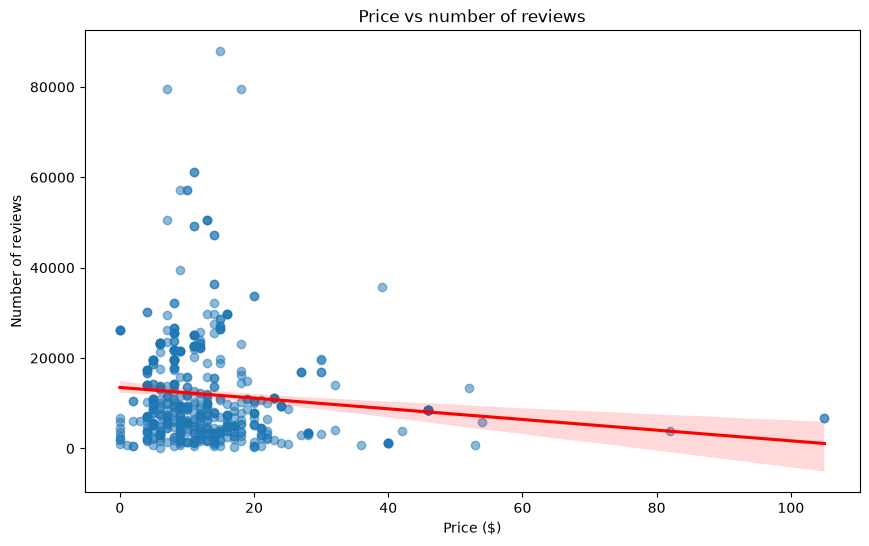

In [23]:
plt.figure(figsize=(10, 6))
sns.regplot(data=Bestsellers, x="Price", y="Reviews",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title("Price vs number of reviews")
plt.xlabel("Price ($)")
plt.ylabel("Number of reviews")
plt.show()

In [ ]:
# ===================== SUMMARY OF RESULTS =====================
# Data: 550 Amazon bestseller entries (top 50 per year, 2009-2019) with
# 7 columns. No missing values and no exact duplicate rows. Only 351
# titles are unique, because many books charted in more than one year.
#
# Methods: converted Year to datetime, used groupby aggregations, and
# made bar, line and scatter charts (seaborn, matplotlib). Tested price
# vs reviews with Pearson and Spearman correlation.
#
# Findings:
# - Mean list price fell from about $15.40 (2009) to about $10.08 (2019).
# - Non Fiction costs more on average than Fiction (about $14.84 vs $10.85).
# - Jeff Kinney has the most bestseller appearances (12). Suzanne Collins,
#   Rick Riordan and Gary Chapman follow with 11 each.
# - Most reviewed: Where the Crawdads Sing (~87,800), The Girl on the
#   Train (~79,400) and Becoming (~61,100).
# - Price and reviews have a very weak negative relationship (Spearman
#   -0.15, Pearson -0.11). Cheaper books tend to have slightly more
#   reviews, but price explains very little of the variation.
#
# Limitations: Price is a list price, not sales. Repeat titles appear in
# several years. Review counts are heavily skewed. 12 books have a price
# of $0, which may be free editions or missing values.
# ==============================================================